- Measure accuracy for devices
- Home settings

In [1]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.preprocessing import StandardScaler
import copy


In [2]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [3]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [4]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [5]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)

In [6]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

KPLITS = 5
RANDOM_STATE = 42
WINDOW_SECONDS = 4

In [7]:
# Outgoing volume
def extract_data_from_pcap(
    file_paths: Iterable[str]
) -> pd.DataFrame:
    columns = [
        "frame.number",
        "frame.time_epoch",
        "frame.len",
        "eth.src",
        "eth.dst",
    ]

    all_data = []

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.number": "int32",
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
                "eth.dst": "category",
            }
        )

        raw_df["capture_id"] = Path(file_path).stem
        all_data.append(raw_df)


    res = pd.concat(all_data, ignore_index=True)
    res = res.sort_values(
        ["frame.time_epoch", "eth.src"],
        ignore_index=True,
    )

    return res


In [8]:
all_data = extract_data_from_pcap(csv_files_1)

In [9]:
def label_features(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]]
) -> pd.DataFrame:

    unknown_macs = set(features["eth.src"]) - set(device_mapping)

    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["eth.src"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["eth.src"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["eth.src"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res

In [10]:
df = all_data.copy()

- A lot of traffic that are Ipv6 multicast neighbor discovery like 33:33:ff:xx:xx:xx. We'll classify if a mac is broadcast, unicast, or multicast
- If the mac are all FF -> broadcast
- Least significant bit of the first octect = 0 -> unicast
- Least significant bit of the first octect = 1 -> multicast

In [11]:
def classify_mac(mac):
    if pd.isna(mac):
        return "invalid"

    mac = str(mac).lower().replace("-", ":")
    parts = mac.split(":")

    if len(parts) != 6:
        return "invalid"

    try:
        octets = [int(x, 16) for x in parts]
    except ValueError:
        return "invalid"

    if octets == [0xff] * 6:
        return "broadcast"

    if octets[0] & 0x01:
        return "multicast"

    return "unicast"

In [12]:
def compute_incoming_and_outgoing_data(df: pd.DataFrame, device_dict_1: dict) -> dict:
    device_info = {}

    for mac in device_dict_1:

        source_mac = mac

        # ============================================================
        # Outgoing traffic
        # source_mac -> destination
        # ============================================================

        outgoing_df = (
            df[df["eth.src"] == source_mac]
            .dropna(subset=["eth.dst"])
            .groupby("eth.dst", observed=True)
            .agg(
                outgoing_packet_count=("frame.len", "size"),
                outgoing_total_bytes=("frame.len", "sum")
            )
            .reset_index()
            .rename(columns={"eth.dst": "peer_mac"})
            .sort_values("outgoing_packet_count", ascending=False)
        )

        outgoing_df["peer_type"] = outgoing_df["peer_mac"].apply(classify_mac)

        # Drop unknown unicast destinations
        outgoing_df = outgoing_df[
            ~(
                (outgoing_df["peer_type"] == "unicast")
                & (~outgoing_df["peer_mac"].isin(device_dict_1.keys()))
            )
        ].copy()

        # Percentage of total outgoing packets/bytes
        outgoing_df["outgoing_packet_count_pct"] = (
            outgoing_df["outgoing_packet_count"]
            / outgoing_df["outgoing_packet_count"].sum()
            * 100
        )

        outgoing_df["outgoing_total_bytes_pct"] = (
            outgoing_df["outgoing_total_bytes"]
            / outgoing_df["outgoing_total_bytes"].sum()
            * 100
        )

        outgoing_df["direction"] = "outgoing"


        # ============================================================
        # Incoming traffic
        # source -> source_mac
        # ============================================================

        incoming_df = (
            df[df["eth.dst"] == source_mac]
            .dropna(subset=["eth.src"])
            .groupby("eth.src", observed=True)
            .agg(
                incoming_packet_count=("frame.len", "size"),
                incoming_total_bytes=("frame.len", "sum")
            )
            .reset_index()
            .rename(columns={"eth.src": "peer_mac"})
            .sort_values("incoming_packet_count", ascending=False)
        )

        incoming_df["peer_type"] = incoming_df["peer_mac"].apply(classify_mac)

        # Drop unknown unicast sources
        incoming_df = incoming_df[
            ~(
                (incoming_df["peer_type"] == "unicast")
                & (~incoming_df["peer_mac"].isin(device_dict_1.keys()))
            )
        ].copy()

        # Percentage of total incoming packets/bytes
        incoming_df["incoming_packet_count_pct"] = (
            incoming_df["incoming_packet_count"]
            / incoming_df["incoming_packet_count"].sum()
            * 100
        )

        incoming_df["incoming_total_bytes_pct"] = (
            incoming_df["incoming_total_bytes"]
            / incoming_df["incoming_total_bytes"].sum()
            * 100
        )

        incoming_df["direction"] = "incoming"


        # ============================================================
        # Store results
        # ============================================================

        print(
            f"Traffic for "
            f"{device_dict_1[source_mac]['device_name']} "
            f"({source_mac})"
        )

        device_info[source_mac] = {
            "device_name": device_dict_1[source_mac]["device_name"],
            "outgoing_traffic_summary": outgoing_df,
            "incoming_traffic_summary": incoming_df
        }

        print("\tOutgoing:")
        display(outgoing_df.sort_values("peer_type"))

        print("\tIncoming:")
        display(incoming_df.sort_values("peer_type"))
        print()
    return device_info

device_info = compute_incoming_and_outgoing_data(df=df, device_dict_1=device_dict_1)

Traffic for Smart Things (d0:52:a8:00:67:5e)
	Outgoing:


,peer_mac,outgoing_packet_count,outgoing_total_bytes,peer_type,outgoing_packet_count_pct,outgoing_total_bytes_pct,direction
2,ff:ff:ff:ff:ff:ff,6113,379188,broadcast,2.102616,1.826085,outgoing
1,14:cc:20:51:33:ea,284620,20385886,unicast,97.897384,98.173915,outgoing


	Incoming:


,peer_mac,incoming_packet_count,incoming_total_bytes,peer_type,incoming_packet_count_pct,incoming_total_bytes_pct,direction
0,14:cc:20:51:33:ea,280308,19224381,unicast,100.0,100.0,incoming



Traffic for Amazon Echo (44:65:0d:56:cc:d3)
	Outgoing:


,peer_mac,outgoing_packet_count,outgoing_total_bytes,peer_type,outgoing_packet_count_pct,outgoing_total_bytes_pct,direction
5,ff:ff:ff:ff:ff:ff,3029,129104,broadcast,0.430932,0.158794,outgoing
0,01:00:5e:00:00:16,1847,99762,multicast,0.262770,0.122705,outgoing
2,01:00:5e:7f:ff:fa,1556,241958,multicast,0.221370,0.297602,outgoing
1,01:00:5e:00:00:fb,37,10505,multicast,0.005264,0.012921,outgoing
4,14:cc:20:51:33:ea,696426,80821261,unicast,99.079663,99.407978,outgoing


... (114 outputs left out)


Traffic for TPLink Router Bridge LAN (Gateway) (14:cc:20:51:33:ea)
	Outgoing:


,peer_mac,outgoing_packet_count,outgoing_total_bytes,peer_type,outgoing_packet_count_pct,outgoing_total_bytes_pct,direction
47,ff:ff:ff:ff:ff:ff,27243,1170016,broadcast,0.221068,1.209959e-02,outgoing
15,33:33:00:00:00:0c,195685,97955690,multicast,1.587920,1.012998e+00,outgoing
7,01:00:5e:7f:ff:fa,64883,31252872,multicast,0.526505,3.231982e-01,outgoing
13,33:33:00:00:00:01,14539,1370866,multicast,0.117979,1.417666e-02,outgoing
22,33:33:ff:51:33:ea,13465,1157990,multicast,0.109264,1.197523e-02,outgoing
16,33:33:00:01:00:02,13465,1157990,multicast,0.109264,1.197523e-02,outgoing
17,33:33:00:01:00:03,13464,1157904,multicast,0.109256,1.197434e-02,outgoing
19,33:33:ff:00:00:01,13464,1157904,multicast,0.109256,1.197434e-02,outgoing
18,33:33:ff:00:00:00,13385,1151110,multicast,0.108615,1.190408e-02,outgoing
14,33:33:00:00:00:02,13373,1150078,multicast,0.108518,1.189341e-02,outgoing


	Incoming:


,peer_mac,incoming_packet_count,incoming_total_bytes,peer_type,incoming_packet_count_pct,incoming_total_bytes_pct,direction
17,74:2f:68:81:69:42,2318577,208892918,unicast,25.665445,14.231978,incoming
9,30:8c:fb:2f:e4:b2,2131288,440445331,unicast,23.592253,30.007759,incoming
12,44:65:0d:56:cc:d3,696426,80821261,unicast,7.709075,5.506393,incoming
20,ac:bc:32:d4:6f:2f,660769,87784886,unicast,7.314370,5.980828,incoming
6,08:21:ef:3b:fc:e3,430077,50686502,unicast,4.760729,3.453297,incoming
5,00:62:6e:51:27:2e,399317,36533356,unicast,4.420232,2.489036,incoming
2,00:24:e4:11:18:a8,350688,27868705,unicast,3.881934,1.898709,incoming
16,70:ee:50:18:34:43,335459,171288996,unicast,3.713357,11.670004,incoming
22,d0:52:a8:00:67:5e,284620,20385886,unicast,3.150596,1.388901,incoming
0,00:16:6c:ab:6b:88,258413,26359197,unicast,2.860498,1.795865,incoming


# Identify Router

In [13]:
unicast_summary = []

for mac, info in device_info.items():

    outgoing_df = info["outgoing_traffic_summary"]
    incoming_df = info["incoming_traffic_summary"]

    outgoing_unicast = outgoing_df[
        outgoing_df["peer_type"] == "unicast"
    ]

    incoming_unicast = incoming_df[
        incoming_df["peer_type"] == "unicast"
    ]

    outgoing_packets = outgoing_unicast["outgoing_packet_count"].sum()
    outgoing_bytes = outgoing_unicast["outgoing_total_bytes"].sum()

    incoming_packets = incoming_unicast["incoming_packet_count"].sum()
    incoming_bytes = incoming_unicast["incoming_total_bytes"].sum()

    unicast_summary.append({
        "mac": mac,
        "device_name": info["device_name"],
        # "outgoing_packet_count": outgoing_packets,
        # "outgoing_total_bytes": outgoing_bytes,
        # "incoming_packet_count": incoming_packets,
        # "incoming_total_bytes": incoming_bytes,
        "total_packet_count": outgoing_packets + incoming_packets,
        "total_bytes": outgoing_bytes + incoming_bytes,
    })

unicast_summary_df = pd.DataFrame(unicast_summary)

display(unicast_summary_df.sort_values(by=["total_packet_count", "total_bytes"], ascending=False))

,mac,device_name,total_packet_count,total_bytes
30,14:cc:20:51:33:ea,TPLink Router Bridge LAN (Gateway),20968980,10998707673
25,74:2f:68:81:69:42,Laptop,6637627,5788791808
5,30:8c:fb:2f:e4:b2,Dropcam,4237764,582473957
26,ac:bc:32:d4:6f:2f,MacBook,2699728,2768224291
12,ec:1a:59:83:28:11,Belkin wemo motion sensor,1422869,356317562
1,44:65:0d:56:cc:d3,Amazon Echo,1333793,362552082
22,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,1102777,604572818
9,ec:1a:59:79:f4:89,Belkin Wemo switch,1086367,270423198
6,00:62:6e:51:27:2e,Insteon Camera Wired,792340,94682456
4,00:16:6c:ab:6b:88,Samsung SmartCam,775616,147969502


In [14]:
features = unicast_summary_df[
    ["total_packet_count", "total_bytes"]
]

# features = unicast_summary_df[
#     ["total_packet_count"]
# ]

# X = np.log1p(features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

unicast_summary_df["cluster"] = kmeans.fit_predict(X_scaled)

display(
    unicast_summary_df[
        [
            "mac",
            "device_name",
            "total_packet_count",
            "total_bytes",
            "cluster"
        ]
    ].sort_values("cluster")
)

,mac,device_name,total_packet_count,total_bytes,cluster
0,d0:52:a8:00:67:5e,Smart Things,564928,39610267,0
28,d0:a6:37:df:a1:e1,IPhone,1969,499412,0
27,b4:ce:f6:a7:a3:c2,Android Phone,105024,72811859,0
26,ac:bc:32:d4:6f:2f,MacBook,2699728,2768224291,0
25,74:2f:68:81:69:42,Laptop,6637627,5788791808,0
24,40:f3:08:ff:1e:da,Android Phone,10580,2797323,0
23,30:8c:fb:b6:ea:45,Nest Dropcam,149730,154903399,0
22,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,1102777,604572818,0
21,70:5a:0f:e4:9b:c0,HP Printer,150813,55309051,0
20,e0:76:d0:33:bb:85,PIX-STAR Photo-frame,56623,12013964,0


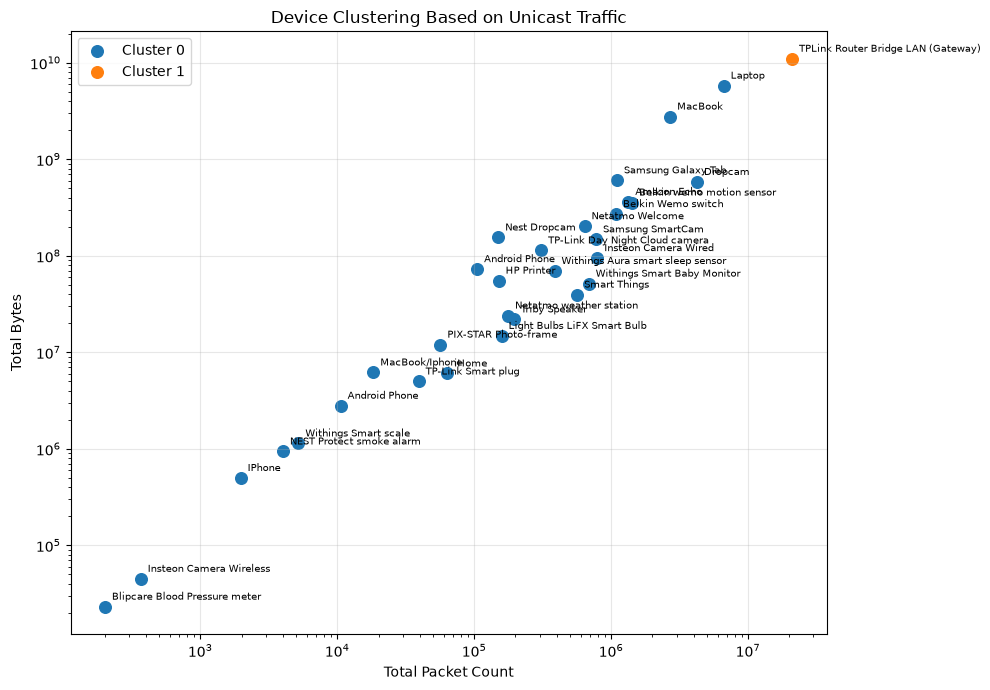

In [15]:
def plotKMeans(unicast_summary_df: pd.DataFrame) -> None:
    plt.figure(figsize=(10, 7))

    for cluster in sorted(unicast_summary_df["cluster"].unique()):

        cluster_df = unicast_summary_df[
            unicast_summary_df["cluster"] == cluster
        ]

        plt.scatter(
            cluster_df["total_packet_count"],
            cluster_df["total_bytes"],
            s=70,
            label=f"Cluster {cluster}"
        )


    # Label every device
    for _, row in unicast_summary_df.iterrows():

        plt.annotate(
            row["device_name"],
            (
                row["total_packet_count"],
                row["total_bytes"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=7
        )


    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel("Total Packet Count")
    plt.ylabel("Total Bytes")

    plt.title("Device Clustering Based on Unicast Traffic")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
plotKMeans(unicast_summary_df)

## Generate Mock Router

In [16]:
GATEWAY_MAC = "14:cc:20:51:33:ea"

In [17]:
def create_mock_gateway_summary(
    device_info,
    unicast_summary_df,
    device_dict,
    gateway_mac,
    n_gateways=3,
    random_state=42,
):
    if n_gateways < 1:
        raise ValueError("n_gateways must be >= 1")

    rng = np.random.default_rng(random_state)

    # ============================================================
    # Create synthetic gateway MACs
    # ============================================================

    mock_gateways = [
        f"02:00:00:00:00:{i + 1:02x}"
        for i in range(n_gateways)
    ]

    main_gateway = rng.choice(mock_gateways)

    # ============================================================
    # Randomly assign devices to gateways
    # ============================================================

    endpoint_devices = [
        mac
        for mac in device_dict
        if mac != gateway_mac
    ]

    shuffled = endpoint_devices.copy()
    rng.shuffle(shuffled)

    device_to_gateway = {
        mac: mock_gateways[i % n_gateways]
        for i, mac in enumerate(shuffled)
    }

    # ============================================================
    # Get original gateway <-> device traffic
    # ============================================================

    gateway_info = device_info[gateway_mac]

    outgoing = gateway_info[
        "outgoing_traffic_summary"
    ].copy()

    incoming = gateway_info[
        "incoming_traffic_summary"
    ].copy()

    # Keep known unicast devices only
    outgoing = outgoing[
        (outgoing["peer_type"] == "unicast")
        & outgoing["peer_mac"].isin(endpoint_devices)
    ].copy()

    incoming = incoming[
        (incoming["peer_type"] == "unicast")
        & incoming["peer_mac"].isin(endpoint_devices)
    ].copy()

    # ============================================================
    # Make one row per peer
    # ============================================================

    outgoing = outgoing[
        [
            "peer_mac",
            "outgoing_packet_count",
            "outgoing_total_bytes",
        ]
    ]

    incoming = incoming[
        [
            "peer_mac",
            "incoming_packet_count",
            "incoming_total_bytes",
        ]
    ]

    peer_traffic = pd.merge(
        outgoing,
        incoming,
        on="peer_mac",
        how="outer",
    ).fillna(0)

    peer_traffic["assigned_gateway"] = (
        peer_traffic["peer_mac"]
        .map(device_to_gateway)
    )

    # ============================================================
    # Aggregate traffic assigned to each gateway
    # ============================================================

    gateway_load = (
        peer_traffic
        .groupby("assigned_gateway", as_index=False)
        .agg(
            original_outgoing_packets=(
                "outgoing_packet_count",
                "sum"
            ),
            original_outgoing_bytes=(
                "outgoing_total_bytes",
                "sum"
            ),
            original_incoming_packets=(
                "incoming_packet_count",
                "sum"
            ),
            original_incoming_bytes=(
                "incoming_total_bytes",
                "sum"
            ),
        )
        .set_index("assigned_gateway")
        .reindex(mock_gateways, fill_value=0)
    )

    # ============================================================
    # Construct synthetic gateway totals
    # ============================================================

    gateway_rows = []

    # Original gateway directional totals
    original_total_out_packets = (
        peer_traffic["outgoing_packet_count"].sum()
    )

    original_total_out_bytes = (
        peer_traffic["outgoing_total_bytes"].sum()
    )

    original_total_in_packets = (
        peer_traffic["incoming_packet_count"].sum()
    )

    original_total_in_bytes = (
        peer_traffic["incoming_total_bytes"].sum()
    )

    for i, gw in enumerate(mock_gateways):

        load = gateway_load.loc[gw]

        if gw == main_gateway:

            # Main gateway sees every original gateway packet once
            outgoing_packets = original_total_out_packets
            outgoing_bytes = original_total_out_bytes

            incoming_packets = original_total_in_packets
            incoming_bytes = original_total_in_bytes

            name = f"Mock Gateway {i + 1} (Main)"

        else:

            # Downstream gateway participates on BOTH links:
            #
            # device <-> downstream GW
            # downstream GW <-> main GW
            #
            # Every original packet therefore contributes
            # one incoming + one outgoing packet.

            traffic_packets = (
                load["original_outgoing_packets"]
                + load["original_incoming_packets"]
            )

            traffic_bytes = (
                load["original_outgoing_bytes"]
                + load["original_incoming_bytes"]
            )

            outgoing_packets = traffic_packets
            incoming_packets = traffic_packets

            outgoing_bytes = traffic_bytes
            incoming_bytes = traffic_bytes

            name = f"Mock Gateway {i + 1}"

        gateway_rows.append({
            "mac": gw,
            "device_name": name,

            "outgoing_packet_count": outgoing_packets,
            "outgoing_total_bytes": outgoing_bytes,

            "incoming_packet_count": incoming_packets,
            "incoming_total_bytes": incoming_bytes,

            "total_packet_count": (
                outgoing_packets
                + incoming_packets
            ),

            "total_bytes": (
                outgoing_bytes
                + incoming_bytes
            ),

            "is_mock_gateway": True,
            "is_main_gateway": gw == main_gateway,
        })

    gateway_summary_df = pd.DataFrame(gateway_rows)

    # ============================================================
    # Keep original endpoint totals
    # ============================================================

    device_summary = unicast_summary_df[
        unicast_summary_df["mac"] != gateway_mac
    ].copy()

    device_summary["is_mock_gateway"] = False
    device_summary["is_main_gateway"] = False

    # ============================================================
    # Combine endpoints + synthetic gateways
    # ============================================================

    result_df = pd.concat(
        [
            device_summary,
            gateway_summary_df,
        ],
        ignore_index=True,
        sort=False,
    )

    # ============================================================
    # Assignment table
    # ============================================================

    assignment_df = pd.DataFrame([
        {
            "device_mac": mac,
            "device_name": device_dict[mac]["device_name"],
            "assigned_gateway": gw,
            "assigned_to_main": gw == main_gateway,
        }
        for mac, gw in device_to_gateway.items()
    ])

    return (
        result_df,
        gateway_summary_df,
        assignment_df,
        main_gateway,
        peer_traffic,
    )

In [24]:
(
    mock_summary_df,
    gateway_summary_df,
    assignment_df,
    main_gateway,
    peer_traffic,
) = create_mock_gateway_summary(
    device_info=device_info,
    unicast_summary_df=unicast_summary_df,
    device_dict=device_dict_1,
    gateway_mac=GATEWAY_MAC,
    n_gateways=3,
    random_state=42,
)

In [25]:
mock_summary_df

,mac,device_name,total_packet_count,total_bytes,cluster,is_mock_gateway,is_main_gateway,outgoing_packet_count,outgoing_total_bytes,incoming_packet_count,incoming_total_bytes
0,d0:52:a8:00:67:5e,Smart Things,564928,39610267,0.0,False,False,NaN,NaN,NaN,NaN
1,44:65:0d:56:cc:d3,Amazon Echo,1333793,362552082,0.0,False,False,NaN,NaN,NaN,NaN
2,70:ee:50:18:34:43,Netatmo Welcome,639308,202764803,0.0,False,False,NaN,NaN,NaN,NaN
3,f4:f2:6d:93:51:f1,TP-Link Day Night Cloud camera,308383,113636406,0.0,False,False,NaN,NaN,NaN,NaN
4,00:16:6c:ab:6b:88,Samsung SmartCam,775616,147969502,0.0,False,False,NaN,NaN,NaN,NaN
5,30:8c:fb:2f:e4:b2,Dropcam,4237764,582473957,0.0,False,False,NaN,NaN,NaN,NaN
6,00:62:6e:51:27:2e,Insteon Camera Wired,792340,94682456,0.0,False,False,NaN,NaN,NaN,NaN
7,e8:ab:fa:19:de:4f,Insteon Camera Wireless,367,45069,0.0,False,False,NaN,NaN,NaN,NaN
8,00:24:e4:11:18:a8,Withings Smart Baby Monitor,685814,51447914,0.0,False,False,NaN,NaN,NaN,NaN
9,ec:1a:59:79:f4:89,Belkin Wemo switch,1086367,270423198,0.0,False,False,NaN,NaN,NaN,NaN


,mac,device_name,total_packet_count,total_bytes,cluster
0,d0:52:a8:00:67:5e,Smart Things,564928,39610267,0
29,f4:5c:89:93:cc:85,MacBook/Iphone,18337,6186525,0
28,d0:a6:37:df:a1:e1,IPhone,1969,499412,0
27,b4:ce:f6:a7:a3:c2,Android Phone,105024,72811859,0
26,ac:bc:32:d4:6f:2f,MacBook,2699728,2768224291,0
25,74:2f:68:81:69:42,Laptop,6637627,5788791808,0
24,40:f3:08:ff:1e:da,Android Phone,10580,2797323,0
23,30:8c:fb:b6:ea:45,Nest Dropcam,149730,154903399,0
22,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,1102777,604572818,0
21,70:5a:0f:e4:9b:c0,HP Printer,150813,55309051,0


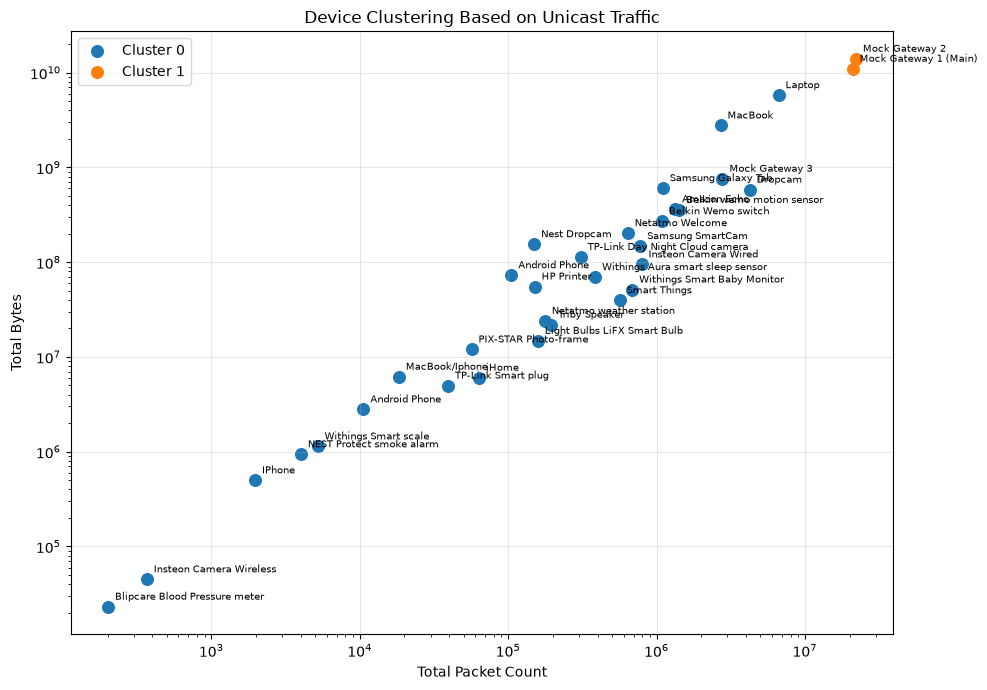

In [26]:
features = mock_summary_df[
    ["total_packet_count", "total_bytes"]
]

# features = mock_unicast_summary_df[
#     ["total_packet_count"]
# ]

# X = np.log1p(features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

mock_summary_df["cluster"] = kmeans.fit_predict(X_scaled)

display(
    mock_summary_df[
        [
            "mac",
            "device_name",
            "total_packet_count",
            "total_bytes",
            "cluster"
        ]
    ].sort_values("cluster")
)
plotKMeans(mock_summary_df)

- I've tried different configuration and laptop keeps showing up which means we can not only rely on the volume (packet count, packet bytes). There can be something else we should add to differentiate macbook from the gateway.
- Another feature we can add is the number of devices communicating with this device. Usually the router will communicate with more devices. So that might help in the clustering?

# Note on September 15th, 2026
- Add more features/dimensions for the KMeans
- Try to cluster IoT vs non-IoT devices
- Try Kaggle dataset